# Баггинг и случайный лес

# Цели обучения

- Установить связь между понятиями «бутстреппинга» и «агрегирования» (более известного как «баггинг») для снижения дисперсии.
- Применить алгоритм «случайного леса», который позволяет ещё больше снизить корреляцию между моделями, построенными методом баггинга.

## Введение

В работе используются данные об оттоке клиентов телекоммуникационной компании (`Orange_Telecom_Churn_Data.csv`), которые рассматривались в первой части курса. Каждая запись описывает одного абонента (тарифные планы, минуты и звонки днём, вечером, ночью, международные звонки, обращения в службу поддержки), а целевая переменная `churned` показывает, ушёл ли клиент.

In [1]:
from __future__ import print_function
import os
import warnings
data_path = ['data']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix

%matplotlib inline

## Вопрос 1. Импорт и подготовка данных

На данном этапе выполняется:

- импорт данных об оттоке клиентов из файла `Orange_Telecom_Churn_Data.csv`;
- удаление столбцов, которые вряд ли будут полезны для прогнозирования;
- кодирование типов данных.

In [2]:
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.csv'])
data = pd.read_csv(filepath, sep=',')
print(data.shape)
data.head()

(5000, 21)


,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,...,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,...,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,...,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,...,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,...,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,...,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


Номер телефона ни в коем случае не должен участвовать в прогнозе, а код города и штат маловероятно понадобятся, если нет оснований считать, что модель учитывает какой-то очень специфический географический фактор. Эти три столбца удаляются.

In [3]:
data = data.drop(['state', 'area_code', 'phone_number'], axis=1)
data.dtypes

account_length                     int64
intl_plan                            str
voice_mail_plan                      str
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

Типы данных выглядят нормально, за исключением того, что `intl_plan` и `voice_mail_plan` (в задании `int_plan`) являются строками «yes»/«no» и должны быть закодированы как булевы значения. Целевая переменная `churned` уже имеет логический тип.

In [4]:
for col in ['intl_plan', 'voice_mail_plan']:
    data[col] = data[col].map({'yes': True, 'no': False})

data.dtypes.value_counts()

float64    8
int64      7
bool       3
Name: count, dtype: int64

In [5]:
data.dtypes

account_length                     int64
intl_plan                           bool
voice_mail_plan                     bool
number_vmail_messages              int64
total_day_minutes                float64
total_day_calls                    int64
total_day_charge                 float64
total_eve_minutes                float64
total_eve_calls                    int64
total_eve_charge                 float64
total_night_minutes              float64
total_night_calls                  int64
total_night_charge               float64
total_intl_minutes               float64
total_intl_calls                   int64
total_intl_charge                float64
number_customer_service_calls      int64
churned                             bool
dtype: object

### Выводы к вопросу 1

* Набор содержит 5 000 записей и 21 столбец. Удалены `state`, `area_code` и `phone_number`: номер телефона — уникальный идентификатор, не несущий информации об оттоке, а штат и код города не имеют очевидной связи с поведением клиента и лишь добавили бы шум.
* `intl_plan` и `voice_mail_plan` были строками «yes»/«no», и их закодировали булевыми значениями (`True`/`False`), так как `sklearn` работает только с числами. Целевая переменная `churned` уже логическая.
* Итог: 17 признаков (8 вещественных, 7 целочисленных, 2 булевых) и целевая переменная. Масштабирование не требуется, так как модели на основе деревьев не чувствительны к масштабу признаков.

## Вопрос 2. Разбиение на обучающую и тестовую выборки

На данном этапе выполняется:

- анализ распределения прогнозируемой переменной `churned`;
- разбиение данных на обучающую и тестовую выборки; на основании распределения принимается решение, нужна ли стратификация;
- сравнение распределения целевой переменной в исходных, обучающих и тестовых данных.

In [6]:
data.churned.value_counts(normalize=True)

churned
False    0.8586
True     0.1414
Name: proportion, dtype: float64

Классы сильно несбалансированы (ушедших клиентов значительно меньше), поэтому данные разбиваются со стратификацией по `churned`.

In [7]:
feature_cols = [x for x in data.columns if x != 'churned']

strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(strat_shuf_split.split(data[feature_cols], data.churned))

X_train = data.loc[train_idx, feature_cols]
y_train = data.loc[train_idx, 'churned']
X_test = data.loc[test_idx, feature_cols]
y_test = data.loc[test_idx, 'churned']
print(X_train.shape, X_test.shape)

(3500, 17) (1500, 17)


Распределение целевой переменной в обучающей и тестовой выборках.

In [8]:
pd.DataFrame({'всего': data.churned.value_counts(normalize=True),
              'train': y_train.value_counts(normalize=True),
              'test': y_test.value_counts(normalize=True)}).round(4)

,всего,train,test
churned,,,
False,0.8586,0.8586,0.8587
True,0.1414,0.1414,0.1413


### Выводы к вопросу 2

* Классы несбалансированы: остались 85,86 % клиентов, ушли только 14,14 %.
* Из-за дисбаланса выбрано **стратифицированное** разбиение `StratifiedShuffleSplit` (70 % / 30 %: 3 500 обучающих и 1 500 тестовых записей, `random_state = 42` для воспроизводимости).
* Доля ушедших клиентов практически одинакова во всех частях (14,14 % в обучающей и 14,13 % в тестовой выборке), то есть тестовая выборка репрезентативна, а метрики на ней можно сравнивать с обучающими.

## Вопрос 3. Случайный лес: ошибка out-of-bag

На данном этапе выполняется:

- построение моделей «случайного леса» с разным количеством деревьев и оценка ошибки out-of-bag (OOB) для каждой из них;
- построение графика ошибки OOB в зависимости от количества деревьев.

Так как меняется только количество деревьев, используется флаг `warm_start=True`: каждая следующая модель достраивает новые деревья к уже существующим. Количество деревьев обновляется методом `set_params`.

In [9]:
# Подавление предупреждений о слишком малом числе деревьев в первых моделях
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [10]:
RF = RandomForestClassifier(oob_score=True, random_state=42, warm_start=True, n_jobs=-1)

oob_list = list()
for n_trees in [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]:
    RF.set_params(n_estimators=n_trees)
    RF.fit(X_train, y_train)
    oob_error = 1 - RF.oob_score_
    oob_list.append(pd.Series({'n_trees': n_trees, 'OOB': oob_error}))

rf_oob_df = pd.concat(oob_list, axis=1).T.astype({'n_trees': int}).set_index('n_trees')
rf_oob_df.round(4)

,OOB
n_trees,
15,0.0597
20,0.0534
30,0.0497
40,0.0474
50,0.0491
100,0.0451
150,0.0449
200,0.0443
300,0.0443


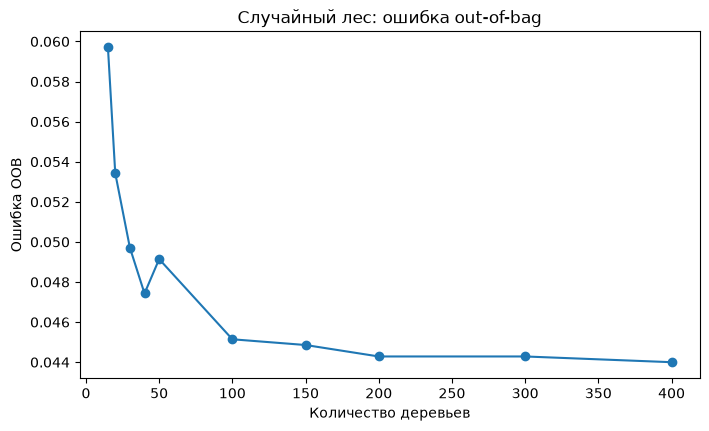

In [11]:
ax = rf_oob_df.plot(marker='o', figsize=(8, 4.5), legend=False)
ax.set(xlabel='Количество деревьев', ylabel='Ошибка OOB', title='Случайный лес: ошибка out-of-bag');

Ошибка стабилизируется при 100–150 деревьях.

### Выводы к вопросу 3

* Ошибка out-of-bag (OOB) — это ошибка, посчитанная для каждого объекта только по тем деревьям, которые его не видели при обучении (бутстреп-выборка содержит около 63 % объектов). Она служит бесплатной оценкой ошибки на новых данных без отдельной валидационной выборки.
* С ростом числа деревьев ошибка быстро падает: 5,97 % (15 деревьев) → 4,74 % (40) → 4,51 % (100) → 4,49 % (150), после чего почти не меняется (4,43 % при 200–300 деревьях, 4,40 % при 400).
* Вывод: ошибка стабилизируется на 100–150 деревьях. Дальнейшее увеличение числа деревьев не вызывает переобучения (усреднение), но почти не улучшает качество и лишь увеличивает время вычислений.

## Вопрос 4. Дополнительные рандомизированные деревья

На данном этапе выполняется:

- повторение задания из вопроса 3 для `ExtraTreesClassifier` (для этой модели параметр `bootstrap` необходимо установить в `True`, иначе ошибка OOB не вычисляется);
- сравнение ошибок OOB двух типов моделей.

In [12]:
EF = ExtraTreesClassifier(oob_score=True, bootstrap=True, random_state=42, warm_start=True, n_jobs=-1)

oob_list = list()
for n_trees in [15, 20, 30, 40, 50, 100, 150, 200, 300, 400]:
    EF.set_params(n_estimators=n_trees)
    EF.fit(X_train, y_train)
    oob_error = 1 - EF.oob_score_
    oob_list.append(pd.Series({'n_trees': n_trees, 'OOB': oob_error}))

et_oob_df = pd.concat(oob_list, axis=1).T.astype({'n_trees': int}).set_index('n_trees')
et_oob_df.round(4)

,OOB
n_trees,
15,0.0811
20,0.0723
30,0.0691
40,0.0640
50,0.0671
100,0.0626
150,0.0611
200,0.0609
300,0.0609


Два датафрейма объединяются в один, чтобы проще построить общий график.

In [13]:
oob_df = pd.concat([rf_oob_df.rename(columns={'OOB': 'RandomForest'}),
                    et_oob_df.rename(columns={'OOB': 'ExtraTrees'})], axis=1)
oob_df.round(4)

,RandomForest,ExtraTrees
n_trees,,
15,0.0597,0.0811
20,0.0534,0.0723
30,0.0497,0.0691
40,0.0474,0.0640
50,0.0491,0.0671
100,0.0451,0.0626
150,0.0449,0.0611
200,0.0443,0.0609
300,0.0443,0.0609


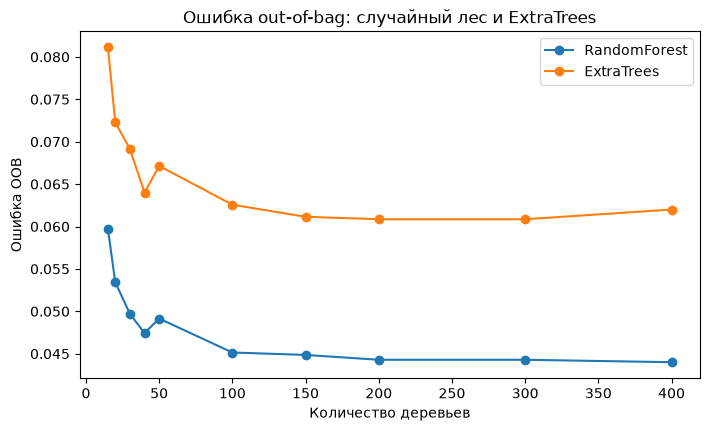

In [14]:
ax = oob_df.plot(marker='o', figsize=(8, 4.5))
ax.set(xlabel='Количество деревьев', ylabel='Ошибка OOB', title='Ошибка out-of-bag: случайный лес и ExtraTrees');

### Выводы к вопросу 4

* `ExtraTreesClassifier` отличается от случайного леса тем, что пороги разбиения выбираются случайно, а не оптимально, то есть добавляется ещё больше случайности.
* Ошибка OOB у ExtraTrees стабильно выше при любом числе деревьев: 6,26 % против 4,51 % при 100 деревьях и около 6,1 % против 4,4 % при 200–400. Кривые не пересекаются.
* Обе кривые выходят на плато примерно при 100–150 деревьях, но случайный лес выходит на более низкий уровень. Поэтому для этих данных лучше подходит случайный лес: дополнительная случайность увеличила смещение больше, чем уменьшила дисперсию.

## Вопрос 5. Метрики качества на тестовой выборке

На данном этапе выполняется:

- выбор одной из хорошо работающих моделей и расчёт показателей ошибок на тестовой выборке;
- анализ того, какая метрика наиболее важна, а какая может вводить в заблуждение с учётом распределения классов.

Выбрана модель случайного леса со 100 деревьями (ошибка OOB к этому количеству уже стабилизировалась).

In [15]:
model = RandomForestClassifier(n_estimators=100, oob_score=True, random_state=42, n_jobs=-1)
model = model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=['Остался (False)', 'Ушёл (True)']))

                 precision    recall  f1-score   support

Остался (False)       0.96      0.99      0.98      1288
    Ушёл (True)       0.94      0.78      0.85       212

       accuracy                           0.96      1500
      macro avg       0.95      0.89      0.92      1500
   weighted avg       0.96      0.96      0.96      1500



In [16]:
scores = pd.Series({'accuracy': accuracy_score(y_test, y_pred),
                    'precision': precision_score(y_test, y_pred),
                    'recall': recall_score(y_test, y_pred),
                    'f1': f1_score(y_test, y_pred),
                    'roc_auc': roc_auc_score(y_test, y_prob)}, name='RandomForest (100)')
print(scores.round(4))
print('Точность тривиальной модели «никто не уходит»:', round(1 - y_test.mean(), 4))

accuracy     0.9620
precision    0.9429
recall       0.7783
f1           0.8527
roc_auc      0.9263
Name: RandomForest (100), dtype: float64
Точность тривиальной модели «никто не уходит»: 0.8587


### Выводы к вопросу 5

* Для модели случайного леса (100 деревьев) на тестовой выборке получены: accuracy = 0,962, precision = 0,943, recall = 0,778, F1 = 0,853, ROC-AUC = 0,926.
* **Вводящая в заблуждение метрика — accuracy.** Тривиальная модель «никто не уходит» уже даёт 0,859, поэтому 0,962 выглядит лучше, чем есть на самом деле: большую часть вклада вносит правильное предсказание класса «остался».
* **Наиболее важная метрика — recall (полнота) для класса «ушёл»** (и F1 как баланс с precision). Задача бизнеса — найти уходящих клиентов, а пропуск такого клиента обходится дороже, чем лишнее предложение удержания. Recall = 0,778 означает, что найдено около 78 % уходящих клиентов; precision = 0,943 означает, что 94 % предсказанных «уходов» правильные.
* Низкая полнота ожидаема: класс «ушёл» редкий (14 %), и модель осторожнее предсказывает именно его. Тем не менее результат заметно лучше случайного угадывания.

## Вопрос 6. Матрица путаницы, кривые и важность признаков

На данном этапе выполняется:

- вывод матрицы путаницы;
- построение кривых ROC и «точность–полнота» (precision–recall);
- построение графика важности признаков.

[[1278   10]
 [  47  165]]


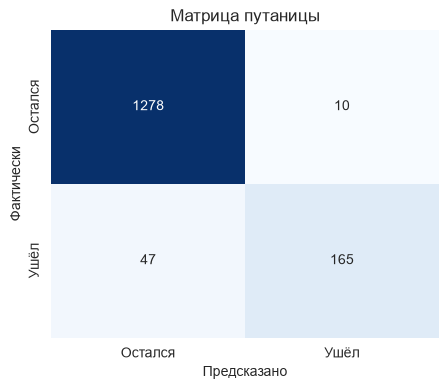

In [17]:
cm = confusion_matrix(y_test, y_pred)
sns.set_style('white')
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['Остался', 'Ушёл'], yticklabels=['Остался', 'Ушёл'])
ax.set(xlabel='Предсказано', ylabel='Фактически', title='Матрица путаницы');
print(cm)

Кривые ROC и «точность–полнота».

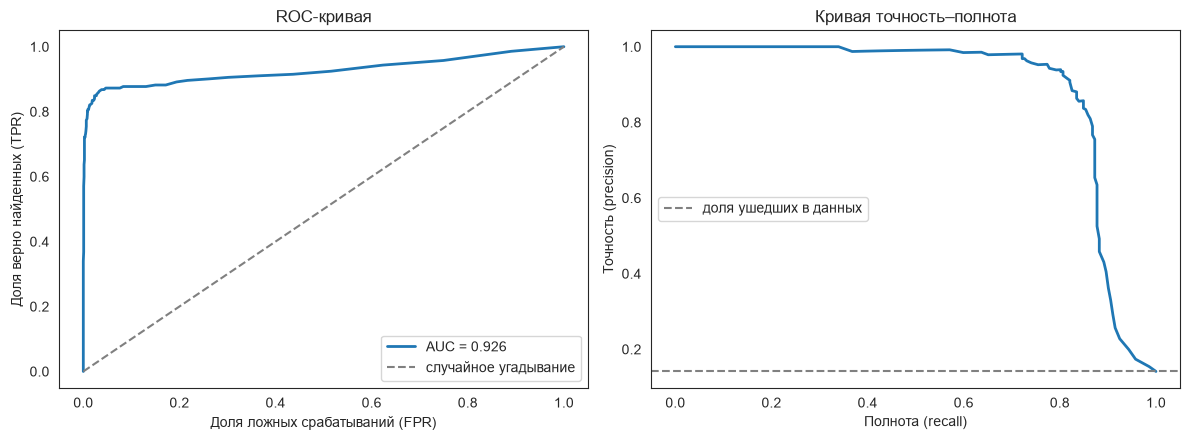

In [18]:
fpr, tpr, _ = roc_curve(y_test, y_prob)
prec, rec, _ = precision_recall_curve(y_test, y_prob)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, lw=2, label=f'AUC = {roc_auc_score(y_test, y_prob):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='случайное угадывание')
axes[0].set(xlabel='Доля ложных срабатываний (FPR)', ylabel='Доля верно найденных (TPR)', title='ROC-кривая')
axes[0].legend(loc='lower right')

axes[1].plot(rec, prec, lw=2)
axes[1].axhline(y_test.mean(), ls='--', color='gray', label='доля ушедших в данных')
axes[1].set(xlabel='Полнота (recall)', ylabel='Точность (precision)', title='Кривая точность–полнота')
axes[1].legend()
plt.tight_layout()

Важность признаков.

total_day_charge                 0.1461
total_day_minutes                0.1407
number_customer_service_calls    0.1077
intl_plan                        0.0813
total_eve_minutes                0.0659
total_eve_charge                 0.0609
total_intl_calls                 0.0579
total_intl_minutes               0.0461
total_intl_charge                0.0420
total_night_minutes              0.0420
total_night_charge               0.0398
account_length                   0.0336
number_vmail_messages            0.0306
total_day_calls                  0.0287
total_night_calls                0.0287
total_eve_calls                  0.0262
voice_mail_plan                  0.0216
dtype: float64

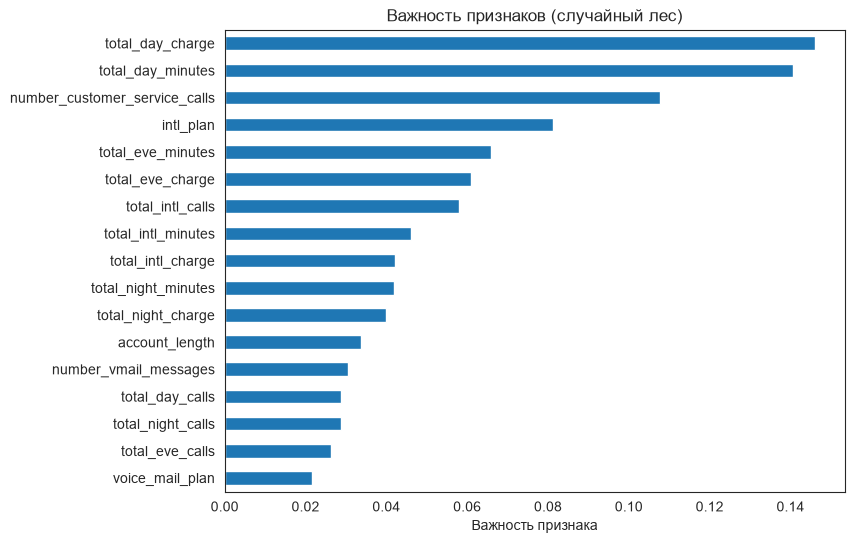

In [19]:
importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
importances.plot.barh(figsize=(8, 6))
plt.xlabel('Важность признака'); plt.title('Важность признаков (случайный лес)');
importances.sort_values(ascending=False).round(4)

### Выводы к вопросу 6

* **Матрица путаницы:** 1 278 верно предсказанных «остался» (TN), 165 верно найденных «ушёл» (TP), 10 ложных тревог (FP) и 47 пропущенных уходящих клиентов (FN). Ошибки сосредоточены в пропусках (FN), что согласуется с recall = 0,778.
* **ROC-кривая** идёт высоко над диагональю (AUC = 0,926), то есть модель хорошо ранжирует клиентов по вероятности ухода. **Кривая точность–полнота** лежит значительно выше доли ушедших в данных (0,14), что подтверждает полезность модели при дисбалансе классов; из неё видно, что рост полноты достигается ценой снижения точности, и порог классификации можно подобрать под нужды бизнеса.
* **Важность признаков:** главные признаки — `total_day_charge` (0,146) и `total_day_minutes` (0,141), затем `number_customer_service_calls` (0,108) и `intl_plan` (0,081). Дневные минуты и дневная стоимость связаны напрямую (стоимость = тариф × минуты), поэтому важность делится между ними; вместе они дают около 29 %. Важность показывает, какие признаки сильнее всего помогают модели, но не направление влияния.

### Общие выводы

* **Баггинг** обучает много деревьев на бутстреп-выборках и усредняет их ответы; это снижает дисперсию отдельного дерева без роста смещения.
* **Случайный лес** дополнительно выбирает на каждом разбиении случайное подмножество признаков, что уменьшает корреляцию между деревьями и ещё сильнее снижает дисперсию ансамбля.
* Ошибка **OOB** позволяет оценить качество без отдельной валидационной выборки; она стабилизируется на 100–150 деревьях.
* На данных об оттоке случайный лес (OOB ≈ 4,5 %) превзошёл ExtraTrees (OOB ≈ 6,2 %) и показал на тесте accuracy 0,962, recall 0,778, ROC-AUC 0,926.
* При несбалансированных классах надёжнее смотреть на recall, precision, F1 и ROC-AUC, а не на accuracy.